# Diabetes Progression Regression
**Applied AI/ML Mini Project** | Problem ID 17 | Rachel Elizabeth Joy (2667213)

Predict a quantitative measure of diabetes disease progression one year after baseline from ten baseline measurements
(`sklearn.datasets.load_diabetes`).

**Focus requirement:** compare Ridge, Lasso and ElasticNet and show how coefficients shrink as regularisation grows.

## 0. Setup
All libraries ship with Colab. A single seed is fixed so every result can be repeated.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, RepeatedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
import sklearn
warnings.filterwarnings('ignore')
SEED = 42
pd.set_option('display.width', 110); pd.set_option('display.max_columns', 20)
np.random.seed(SEED)
plt.style.use('grayscale')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white'})
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


## 1. Problem statement
The target is a quantitative measure of disease progression one year after baseline (range about 25 to 346).
A clinician or care-planning team could use the prediction to flag patients likely to progress fastest.
**Main metric: RMSE** (same units as the target, penalises large misses). MAE and R² are reported alongside.

## 2. Load and describe the data
`scaled=False` loads the original units so that scaling is done by us, inside the pipeline, on training data only.

In [2]:
raw = load_diabetes(as_frame=True, scaled=False)
data = raw.frame.rename(columns={'s1': 'tc', 's2': 'ldl', 's3': 'hdl',
                                 's4': 'tch', 's5': 'ltg', 's6': 'glu'})
print('Shape:', data.shape)
display(data.head())
data.info()

Shape: (442, 11)


,age,sex,bmi,bp,tc,ldl,hdl,tch,ltg,glu,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   tc      442 non-null    float64
 5   ldl     442 non-null    float64
 6   hdl     442 non-null    float64
 7   tch     442 non-null    float64
 8   ltg     442 non-null    float64
 9   glu     442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [3]:
display(data.describe().T.round(2))
print('Missing values per column:'); print(data.isna().sum().to_string())
print('Sex value counts:'); print(data['sex'].value_counts().to_string())

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
tc,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
ldl,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
hdl,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
tch,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
ltg,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
glu,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00


Missing values per column:
age       0
sex       0
bmi       0
bp        0
tc        0
ldl       0
hdl       0
tch       0
ltg       0
glu       0
target    0
Sex value counts:
sex
1.0    235
2.0    207


## 3. Exploratory data analysis

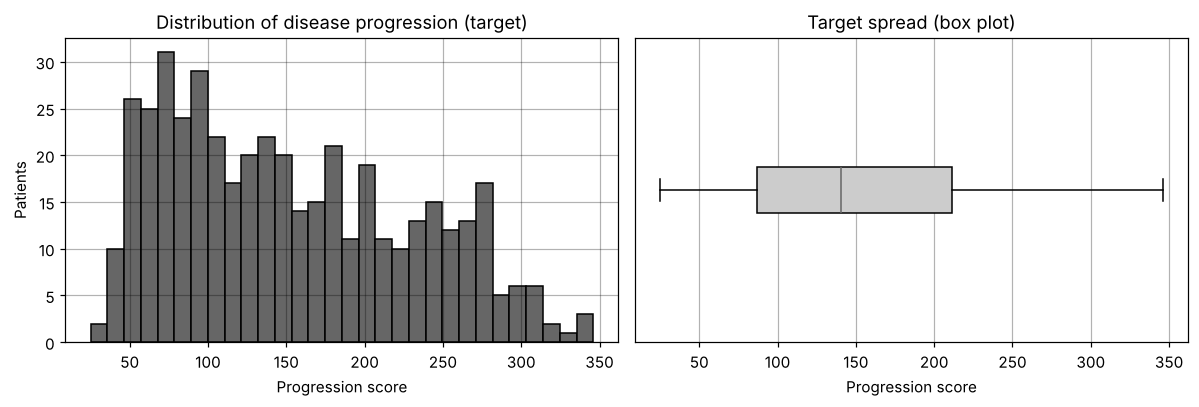

Skewness of target: 0.441


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(data['target'], bins=30, color='0.4', edgecolor='black')
ax[0].set(title='Distribution of disease progression (target)', xlabel='Progression score', ylabel='Patients')
ax[1].boxplot(data['target'], vert=False, patch_artist=True, boxprops=dict(facecolor='0.8'))
ax[1].set(title='Target spread (box plot)', xlabel='Progression score', yticks=[])
plt.tight_layout(); plt.savefig('fig_target.png', dpi=150); plt.show()
print('Skewness of target:', round(data['target'].skew(), 3))

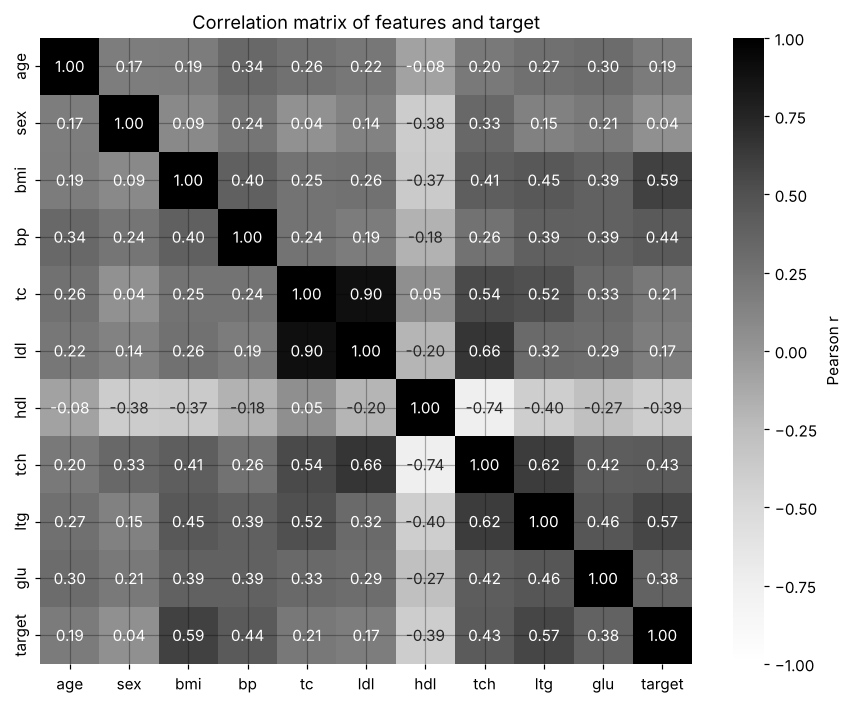

bmi    0.586
ltg    0.566
bp     0.441
tch    0.430
glu    0.382
tc     0.212
age    0.188
ldl    0.174
sex    0.043
hdl   -0.395


In [5]:
corr = data.corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Greys', vmin=-1, vmax=1, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation matrix of features and target')
plt.tight_layout(); plt.savefig('fig_corr.png', dpi=150); plt.show()
print(corr['target'].drop('target').sort_values(ascending=False).round(3).to_string())

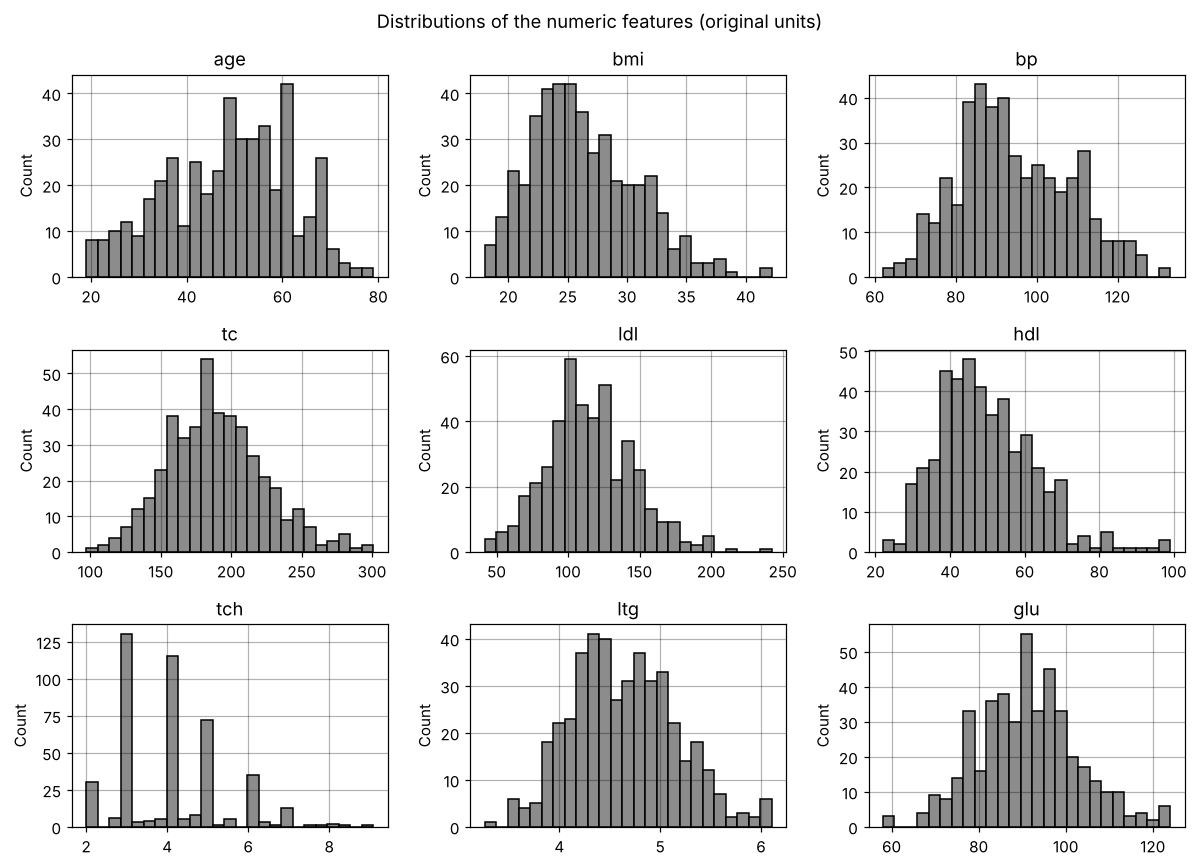

In [6]:
feats = [c for c in data.columns if c not in ('target', 'sex')]
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for a, f in zip(axes.ravel(), feats):
    a.hist(data[f], bins=25, color='0.55', edgecolor='black')
    a.set(title=f, ylabel='Count')
plt.suptitle('Distributions of the numeric features (original units)')
plt.tight_layout(); plt.savefig('fig_feat_hist.png', dpi=150); plt.show()

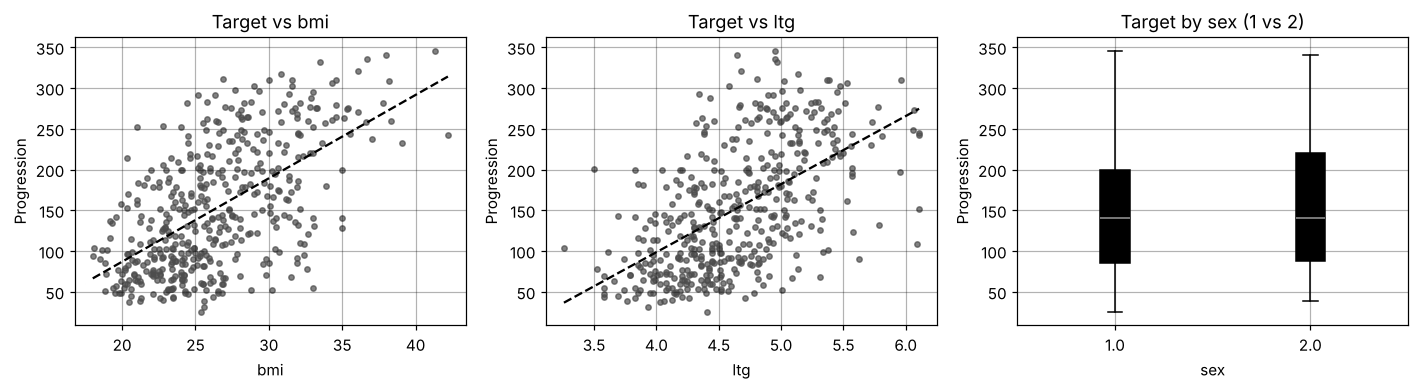

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, f in zip(ax[:2], ['bmi', 'ltg']):
    a.scatter(data[f], data['target'], s=12, c='0.3', alpha=0.7)
    m, b = np.polyfit(data[f], data['target'], 1)
    xs = np.linspace(data[f].min(), data[f].max(), 50); a.plot(xs, m*xs + b, 'k--', lw=1.5)
    a.set(title=f'Target vs {f}', xlabel=f, ylabel='Progression')
data.boxplot(column='target', by='sex', ax=ax[2], patch_artist=True)
ax[2].set(title='Target by sex (1 vs 2)', xlabel='sex', ylabel='Progression'); plt.suptitle('')
plt.tight_layout(); plt.savefig('fig_scatter.png', dpi=150); plt.show()

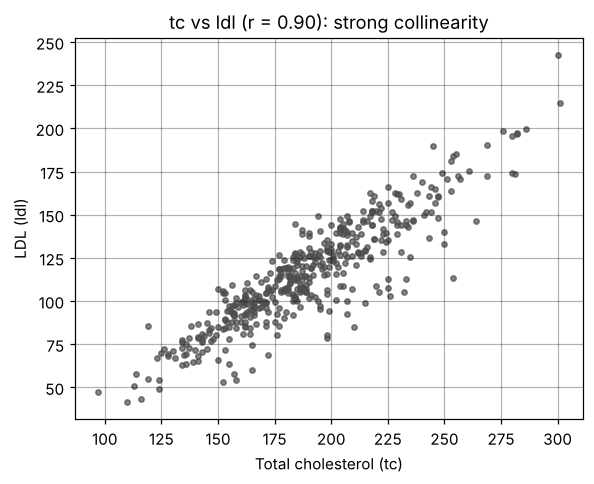

In [8]:
plt.figure(figsize=(5.5, 4.5))
plt.scatter(data['tc'], data['ldl'], s=12, c='0.3', alpha=0.7)
plt.title(f"tc vs ldl (r = {data['tc'].corr(data['ldl']):.2f}): strong collinearity")
plt.xlabel('Total cholesterol (tc)'); plt.ylabel('LDL (ldl)')
plt.tight_layout(); plt.savefig('fig_collinear.png', dpi=150); plt.show()

**Observations.** The target is right-skewed with no missing values. `bmi` and `ltg` correlate most strongly with
progression (r ≈ 0.59 and 0.57). `tc` and `ldl` are almost collinear (r ≈ 0.90), and `hdl` is negatively related
to the target. Collinearity is exactly the situation in which Ridge, Lasso and ElasticNet behave differently.

## 4. Data preparation and feature engineering
The split is made **before** any fitting. Imputation, encoding and scaling live inside a pipeline, so they are learnt from training folds only.

In [9]:
X = data.drop(columns='target'); y = data['target']
# 60 / 20 / 20 split, stratified on target quintiles so all splits cover the full range
bins = pd.qcut(y, 5, labels=False)
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=bins)
bins_tmp = pd.qcut(y_tmp, 5, labels=False)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED, stratify=bins_tmp)
for n, (a, b) in {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}.items():
    print(f'{n:<11} X={a.shape}  y={b.shape}  target mean={b.mean():6.1f}')

Train       X=(264, 10)  y=(264,)  target mean= 152.3
Validation  X=(89, 10)  y=(89,)  target mean= 150.8
Test        X=(89, 10)  y=(89,)  target mean= 152.9


In [10]:
def add_features(df):
    df = df.copy()
    df['bmi_x_bp'] = df['bmi'] * df['bp']          # combined metabolic load: obesity x blood pressure
    df['ldl_hdl_ratio'] = df['ldl'] / df['hdl']    # clinical lipid risk ratio
    return df

num_cols = ['age', 'bmi', 'bp', 'tc', 'ldl', 'hdl', 'tch', 'ltg', 'glu', 'bmi_x_bp', 'ldl_hdl_ratio']
cat_cols = ['sex']
pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))]), cat_cols)])
feat_eng = FunctionTransformer(add_features)
def make_pipe(model):
    return Pipeline([('features', feat_eng), ('prep', pre), ('model', model)])
print(make_pipe(Ridge()))

Pipeline(steps=[('features',
                 FunctionTransformer(func=<function add_features at 0x7f6e9e6937e0>)),
                ('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('impute',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi', 'bp', 'tc',
                                                   'ldl', 'hdl', 'tch', 'ltg',
                                                   'glu', 'bmi_x_bp',
                                                   'ldl_hdl_ratio']),
                                                 ('cat',
                                                  Pipeline(steps=[('impute',
                             

In [11]:
Xt = make_pipe(Ridge()).fit(X_train, y_train)[:-1].transform(X_train)
feature_names = num_cols + ['sex_2']
print('Transformed training matrix:', Xt.shape)
print('Means after scaling (train):', np.round(Xt[:, :len(num_cols)].mean(0), 3))
print('Std after scaling (train):  ', np.round(Xt[:, :len(num_cols)].std(0), 3))
eng = add_features(X_train)
print('Correlation of engineered features with target (train):')
print(eng[['bmi_x_bp', 'ldl_hdl_ratio']].corrwith(y_train).round(3).to_string())

Transformed training matrix: (264, 12)
Means after scaling (train): [ 0. -0.  0.  0. -0.  0. -0.  0. -0. -0.  0.]
Std after scaling (train):   [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Correlation of engineered features with target (train):
bmi_x_bp         0.634
ldl_hdl_ratio    0.257


## 5. Models and experimental setup
Baseline: predict the training mean. Then OLS, three regularised linear models (tuned), and two tree ensembles. All tuning uses 5-fold × 3-repeat cross-validation on the training set only.

In [12]:
cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
alphas = np.logspace(-3, 3, 61)
grids = {
    'Ridge':      (Ridge(random_state=SEED),                    {'model__alpha': alphas}),
    'Lasso':      (Lasso(max_iter=50000, random_state=SEED),    {'model__alpha': np.logspace(-3, 2, 51)}),
    'ElasticNet': (ElasticNet(max_iter=50000, random_state=SEED),
                   {'model__alpha': np.logspace(-3, 2, 26), 'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}),
}
tuned = {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(make_pipe(est), grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=-1)
    gs.fit(X_train, y_train); tuned[name] = gs
    print(f'{name:<11} best {gs.best_params_}  CV RMSE = {-gs.best_score_:.2f}')

Ridge       best {'model__alpha': np.float64(19.952623149688787)}  CV RMSE = 55.44


Lasso       best {'model__alpha': np.float64(0.3981071705534973)}  CV RMSE = 55.32


ElasticNet  best {'model__alpha': np.float64(0.3981071705534973), 'model__l1_ratio': 0.9}  CV RMSE = 55.39


In [13]:
rf_grid = {'model__n_estimators': [200, 400], 'model__max_depth': [3, 5, 8, None],
           'model__min_samples_leaf': [2, 5, 10], 'model__max_features': [0.33, 0.5, 1.0]}
gb_grid = {'model__n_estimators': [100, 200, 400], 'model__learning_rate': [0.01, 0.03, 0.1],
           'model__max_depth': [2, 3], 'model__subsample': [0.7, 1.0], 'model__min_samples_leaf': [5, 10]}
for name, est, grid in [('RandomForest', RandomForestRegressor(random_state=SEED), rf_grid),
                        ('GradBoost', GradientBoostingRegressor(random_state=SEED), gb_grid)]:
    rs = RandomizedSearchCV(make_pipe(est), grid, n_iter=25, cv=cv, random_state=SEED,
                            scoring='neg_root_mean_squared_error', n_jobs=-1)
    rs.fit(X_train, y_train); tuned[name] = rs
    print(f'{name:<12} best {rs.best_params_}  CV RMSE = {-rs.best_score_:.2f}')

RandomForest best {'model__n_estimators': 200, 'model__min_samples_leaf': 5, 'model__max_features': 0.33, 'model__max_depth': None}  CV RMSE = 56.70


GradBoost    best {'model__subsample': 0.7, 'model__n_estimators': 400, 'model__min_samples_leaf': 10, 'model__max_depth': 2, 'model__learning_rate': 0.01}  CV RMSE = 57.01


## 6. Results
Every model is compared on the **same** CV folds and the **same** validation set. The test set is still untouched.

In [14]:
models = {'Baseline (mean)': make_pipe(DummyRegressor()), 'OLS': make_pipe(LinearRegression())}
models.update({k: v.best_estimator_ for k, v in tuned.items()})
rows = []
for name, m in models.items():
    cvres = cross_validate(m, X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    m.fit(X_train, y_train); p = m.predict(X_val)
    rows.append({'Model': name, 'CV RMSE': -cvres['test_score'].mean(), 'CV RMSE sd': cvres['test_score'].std(),
                 'Val RMSE': mean_squared_error(y_val, p) ** 0.5, 'Val MAE': mean_absolute_error(y_val, p),
                 'Val R2': r2_score(y_val, p)})
results = pd.DataFrame(rows).set_index('Model').round(3)
display(results)

,CV RMSE,CV RMSE sd,Val RMSE,Val MAE,Val R2
Model,,,,,
Baseline (mean),76.720,5.565,77.749,65.636,-0.000
OLS,55.694,4.875,56.488,46.277,0.472
Ridge,55.445,4.830,55.842,45.311,0.484
Lasso,55.323,5.042,55.884,45.440,0.483
ElasticNet,55.391,4.952,55.792,45.395,0.485
RandomForest,56.705,4.913,57.058,46.566,0.461
GradBoost,57.013,5.925,56.905,46.409,0.464


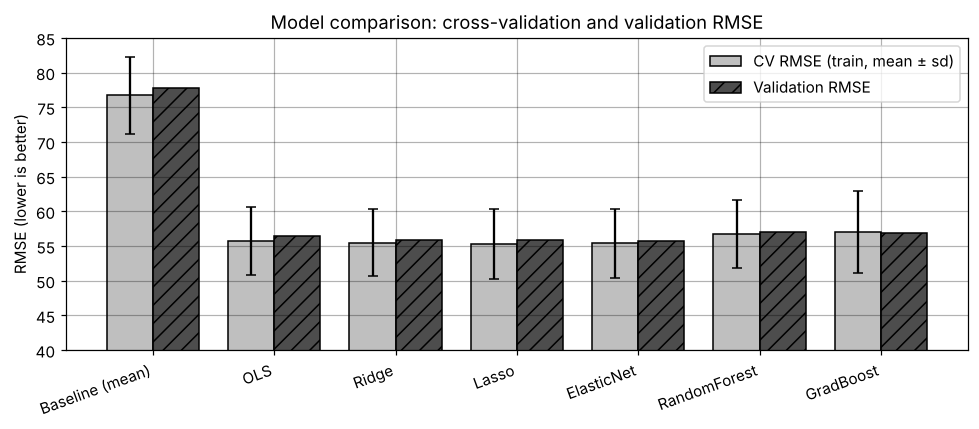

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
idx = np.arange(len(results)); w = 0.38
ax.bar(idx - w/2, results['CV RMSE'], w, yerr=results['CV RMSE sd'], capsize=3, color='0.75', edgecolor='black', label='CV RMSE (train, mean ± sd)')
ax.bar(idx + w/2, results['Val RMSE'], w, color='0.3', edgecolor='black', hatch='//', label='Validation RMSE')
ax.set_xticks(idx); ax.set_xticklabels(results.index, rotation=20, ha='right')
ax.set(ylabel='RMSE (lower is better)', title='Model comparison: cross-validation and validation RMSE', ylim=(40, 85))
ax.legend(); plt.tight_layout(); plt.savefig('fig_compare.png', dpi=150); plt.show()

**Model choice.** The regularised linear models and OLS are within about one CV standard deviation of each other and
clearly beat the baseline; the tree ensembles do not beat them on 265 training rows. The final model is chosen by
lowest CV RMSE (validation RMSE breaks ties), refit on train + validation, and scored **once** on the test set.

In [16]:
lin = results.drop(index=['Baseline (mean)'])
best_name = lin['CV RMSE'].idxmin()
print('Selected model:', best_name)
final = models[best_name]
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final.fit(X_trval, y_trval)
p_test = final.predict(X_test)
test_scores = {'Test RMSE': mean_squared_error(y_test, p_test) ** 0.5,
               'Test MAE': mean_absolute_error(y_test, p_test), 'Test R2': r2_score(y_test, p_test)}
base_test = make_pipe(DummyRegressor()).fit(X_trval, y_trval).predict(X_test)
print({k: round(v, 3) for k, v in test_scores.items()})
print('Baseline test RMSE for reference:', round(mean_squared_error(y_test, base_test) ** 0.5, 3))

Selected model: Lasso
{'Test RMSE': 52.213, 'Test MAE': 41.63, 'Test R2': 0.548}
Baseline test RMSE for reference: 77.651


## 7. Focus requirement: Ridge vs Lasso vs ElasticNet coefficient shrinkage
Each model is refit on the scaled training matrix across a grid of α. The CV-chosen α from Section 5 is marked on each path.

In [17]:
prep_only = Pipeline([('features', feat_eng), ('prep', pre)]).fit(X_train)
Xs = prep_only.transform(X_train)
l1r = tuned['ElasticNet'].best_params_['model__l1_ratio']
path_alphas = np.logspace(-3, 3, 80)
makers = {'Ridge': lambda a: Ridge(alpha=a), 'Lasso': lambda a: Lasso(alpha=a, max_iter=50000),
          f'ElasticNet (l1_ratio={l1r})': lambda a: ElasticNet(alpha=a, l1_ratio=l1r, max_iter=50000)}
paths = {k: np.array([f(a).fit(Xs, y_train).coef_ for a in path_alphas]) for k, f in makers.items()}
best_alpha = {k: tuned[k.split()[0]].best_params_['model__alpha'] for k in makers}
coef_at_best = pd.DataFrame({k: f(best_alpha[k]).fit(Xs, y_train).coef_ for k, f in makers.items()},
                            index=feature_names)
coef_at_best['OLS'] = LinearRegression().fit(Xs, y_train).coef_
display(coef_at_best.round(2))
print('Non-zero coefficients:', (coef_at_best.abs() > 1e-6).sum().to_dict())

,Ridge,Lasso,ElasticNet (l1_ratio=0.9),OLS
age,2.30,2.19,2.03,3.90
bmi,12.92,0.00,9.93,-39.51
bp,4.17,-6.76,1.10,-41.60
tc,-0.96,-3.59,-1.73,-22.80
ldl,-2.76,-0.00,-1.99,21.17
hdl,-9.22,-8.92,-8.55,-6.25
tch,0.26,-0.00,-0.00,-2.00
ltg,23.44,26.04,24.49,34.08
glu,3.65,3.06,3.23,4.07
bmi_x_bp,19.54,40.34,24.68,101.96


Non-zero coefficients: {'Ridge': 12, 'Lasso': 9, 'ElasticNet (l1_ratio=0.9)': 11, 'OLS': 12}


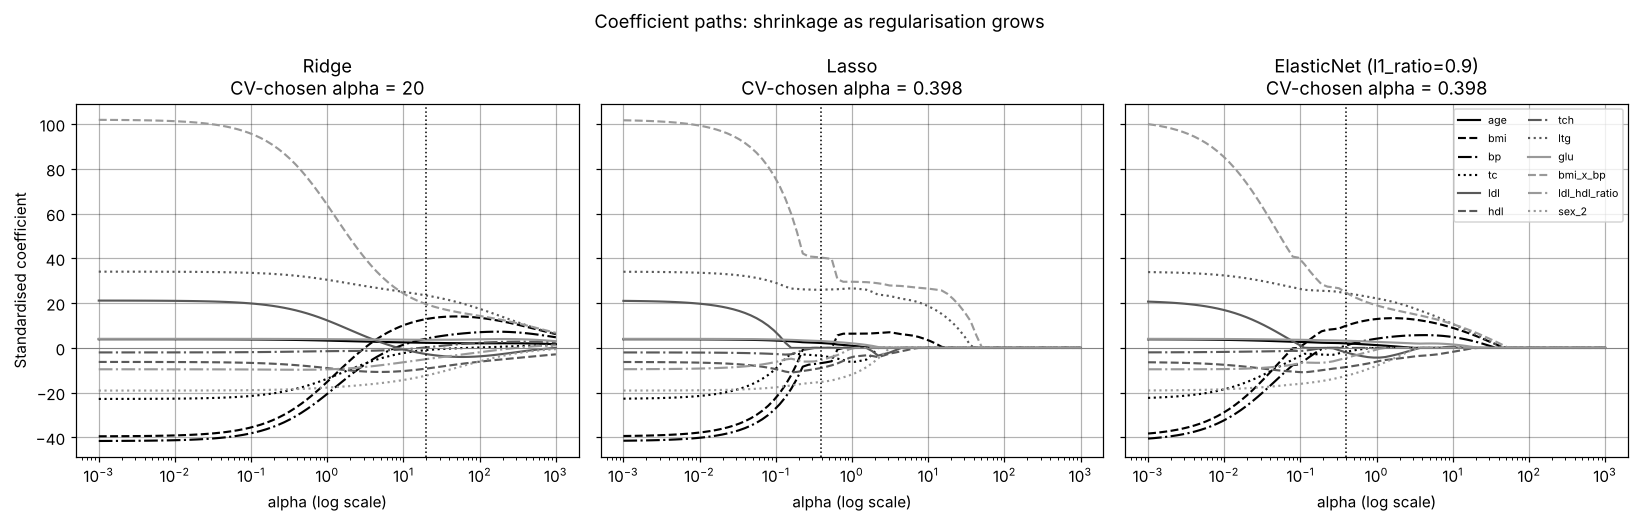

In [18]:
styles = ['-', '--', '-.', ':']; greys = ['0.0', '0.35', '0.6']
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, (k, P) in zip(axes, paths.items()):
    for j, f in enumerate(feature_names):
        ax.plot(path_alphas, P[:, j], ls=styles[j % 4], color=greys[j // 4], lw=1.4, label=f)
    ax.axvline(best_alpha[k], color='black', lw=1, ls=':'); ax.axhline(0, color='0.5', lw=0.6)
    ax.set(xscale='log', title=f'{k}\nCV-chosen alpha = {best_alpha[k]:.3g}', xlabel='alpha (log scale)')
axes[0].set_ylabel('Standardised coefficient')
axes[2].legend(fontsize=7, ncol=2, loc='upper right')
plt.suptitle('Coefficient paths: shrinkage as regularisation grows')
plt.tight_layout(); plt.savefig('fig_paths.png', dpi=150); plt.show()

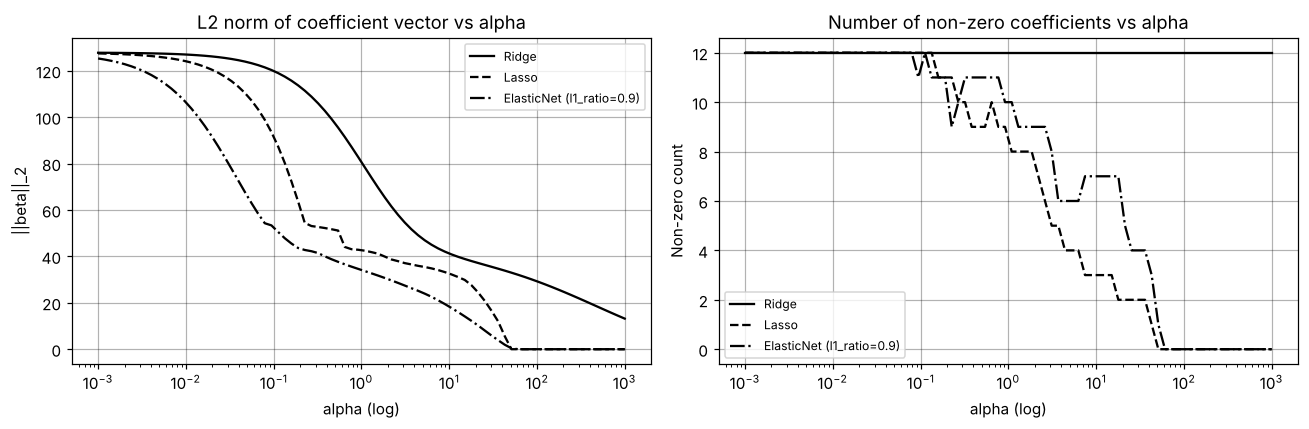

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (k, P), ls in zip(paths.items(), ['-', '--', '-.']):
    ax[0].plot(path_alphas, np.linalg.norm(P, axis=1), ls=ls, color='black', label=k)
    ax[1].plot(path_alphas, (np.abs(P) > 1e-6).sum(1), ls=ls, color='black', label=k)
ax[0].set(xscale='log', title='L2 norm of coefficient vector vs alpha', xlabel='alpha (log)', ylabel='||beta||_2')
ax[1].set(xscale='log', title='Number of non-zero coefficients vs alpha', xlabel='alpha (log)', ylabel='Non-zero count')
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('fig_norms.png', dpi=150); plt.show()

In [20]:
# alpha at which each feature first becomes exactly zero (and stays zero) on the Lasso path
P = paths['Lasso']; drop_alpha = {}
for j, f in enumerate(feature_names):
    nz = np.where(np.abs(P[:, j]) > 1e-6)[0]
    drop_alpha[f] = path_alphas[nz.max() + 1] if len(nz) and nz.max() + 1 < len(path_alphas) else (path_alphas[0] if not len(nz) else np.inf)
order = pd.Series(drop_alpha).sort_values()
print('Lasso: alpha beyond which each coefficient stays exactly zero (earliest at top)')
print('Zero at the CV-chosen alpha:', [f for f in feature_names if abs(coef_at_best.loc[f, "Lasso"]) < 1e-6])
print(order.map(lambda v: f'{v:.3g}').to_string())
cv_curve = pd.DataFrame(tuned['Lasso'].cv_results_)[['param_model__alpha', 'mean_test_score']]
print('\nLasso CV RMSE at selected alphas:')
print(cv_curve.iloc[::10].assign(RMSE=lambda d: -d.mean_test_score)[['param_model__alpha', 'RMSE']].round(2).to_string(index=False))

Lasso: alpha beyond which each coefficient stays exactly zero (earliest at top)
Zero at the CV-chosen alpha: ['bmi', 'ldl', 'tch']
tch              0.382
bp               0.769
ldl_hdl_ratio     1.09
age               1.84
tc                 2.2
glu               2.62
sex_2             3.12
ldl               4.42
hdl               7.47
bmi               17.9
ltg               42.9
bmi_x_bp          51.2

Lasso CV RMSE at selected alphas:
 param_model__alpha  RMSE
               0.00 55.69
               0.01 55.66
               0.10 55.51
               1.00 55.35
              10.00 56.53
             100.00 76.72


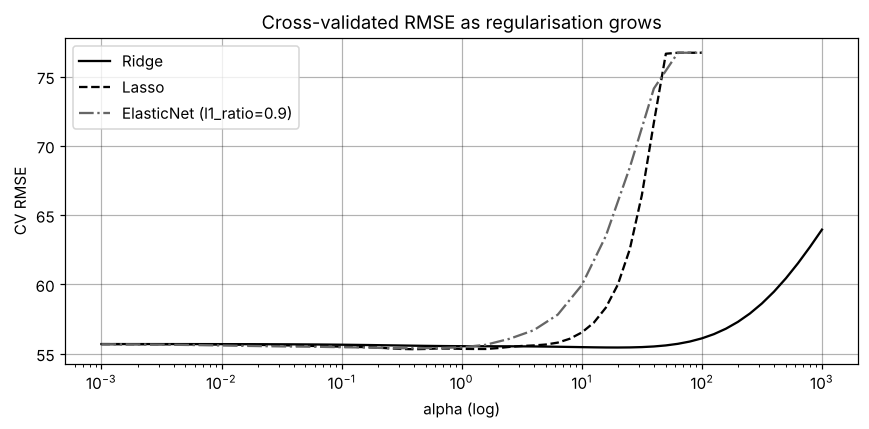

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, ls in [('Ridge', '-'), ('Lasso', '--')]:
    r = pd.DataFrame(tuned[k].cv_results_)
    ax.plot(r['param_model__alpha'].astype(float), -r['mean_test_score'], ls=ls, color='black', label=k)
r = pd.DataFrame(tuned['ElasticNet'].cv_results_); r = r[r['param_model__l1_ratio'] == l1r]
ax.plot(r['param_model__alpha'].astype(float), -r['mean_test_score'], ls='-.', color='0.4', label=f'ElasticNet (l1_ratio={l1r})')
ax.set(xscale='log', xlabel='alpha (log)', ylabel='CV RMSE', title='Cross-validated RMSE as regularisation grows')
ax.legend(); plt.tight_layout(); plt.savefig('fig_cvcurve.png', dpi=150); plt.show()

## 8. Error analysis and interpretation
Residuals use the single set of test predictions made above; nothing is re-tuned after this. Feature importance uses the validation set.

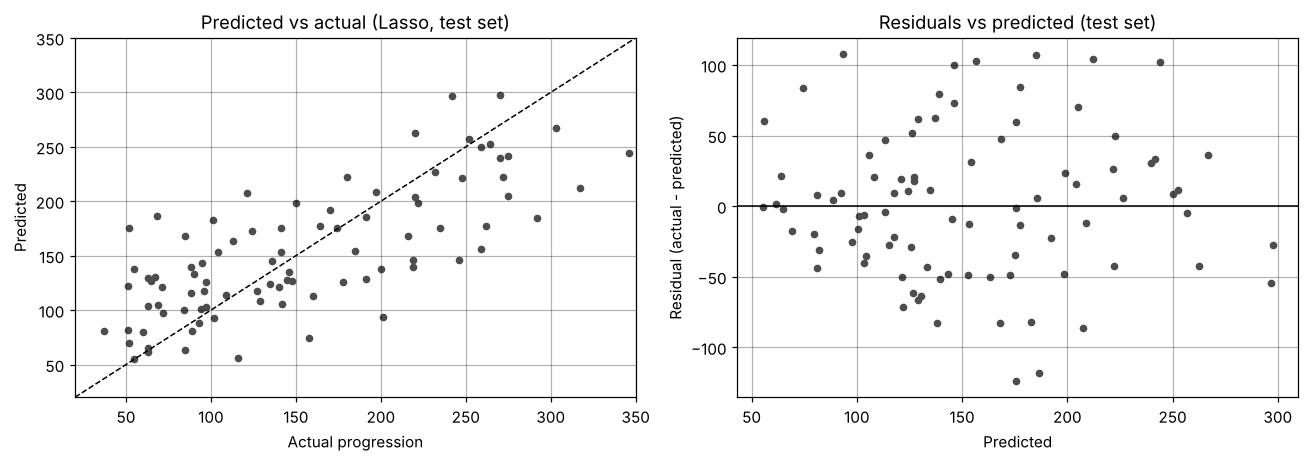

Test error by actual-target quartile:
          MAE  mean_residual
q                           
Q1 low   45.8          -43.9
Q2       29.3          -16.9
Q3       41.8           28.5
Q4 high  50.0           38.2


In [22]:
resid = y_test - p_test
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].scatter(y_test, p_test, s=16, c='0.3'); lim = [20, 350]; ax[0].plot(lim, lim, 'k--', lw=1)
ax[0].set(title=f'Predicted vs actual ({best_name}, test set)', xlabel='Actual progression', ylabel='Predicted', xlim=lim, ylim=lim)
ax[1].scatter(p_test, resid, s=16, c='0.3'); ax[1].axhline(0, color='black', lw=1)
ax[1].set(title='Residuals vs predicted (test set)', xlabel='Predicted', ylabel='Residual (actual - predicted)')
plt.tight_layout(); plt.savefig('fig_resid.png', dpi=150); plt.show()
q = pd.qcut(y_test, 4, labels=['Q1 low', 'Q2', 'Q3', 'Q4 high'])
print('Test error by actual-target quartile:')
print(pd.DataFrame({'q': q, 'abs_err': resid.abs(), 'bias': resid}).groupby('q', observed=True).agg(MAE=('abs_err', 'mean'), mean_residual=('bias', 'mean')).round(1).to_string())

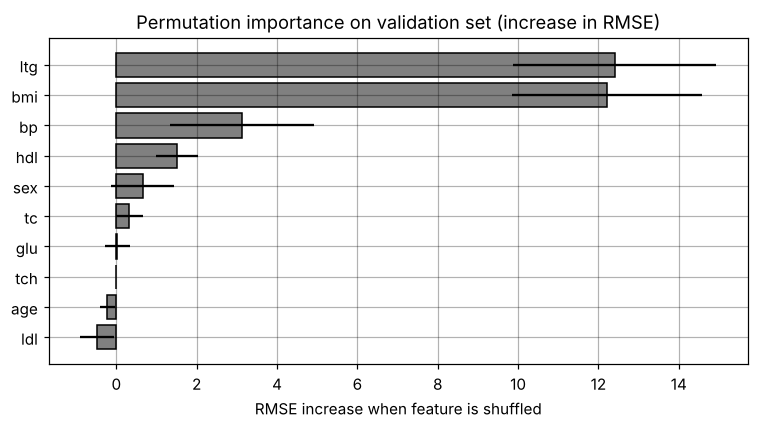

In [23]:
# importance is measured on the VALIDATION set with a copy fit on train only, so the test set is used once
from sklearn.base import clone
m_tr = clone(final).fit(X_train, y_train)
pi = permutation_importance(m_tr, X_val, y_val, n_repeats=30, random_state=SEED, scoring='neg_root_mean_squared_error')
order_i = np.argsort(pi.importances_mean)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(X_val.columns[order_i], pi.importances_mean[order_i], xerr=pi.importances_std[order_i], color='0.5', edgecolor='black')
ax.set(title='Permutation importance on validation set (increase in RMSE)', xlabel='RMSE increase when feature is shuffled')
plt.tight_layout(); plt.savefig('fig_importance.png', dpi=150); plt.show()

In [24]:
worst = X_test.assign(actual=y_test, predicted=p_test.round(1), residual=resid.round(1))
worst = worst.reindex(worst['residual'].abs().sort_values(ascending=False).index).head(8)
display(worst[['age', 'sex', 'bmi', 'bp', 'ltg', 'hdl', 'actual', 'predicted', 'residual']])
print('Median bmi / ltg in training data:', X_train['bmi'].median(), '/', round(X_train['ltg'].median(), 2))

,age,sex,bmi,bp,ltg,hdl,actual,predicted,residual
380,53.0,1.0,28.8,111.67,4.0775,46.0,52.0,175.8,-123.8
289,28.0,2.0,31.5,83.00,5.3132,38.0,68.0,186.5,-118.5
387,36.0,1.0,27.8,73.00,3.4965,42.0,201.0,93.4,107.6
190,51.0,1.0,25.2,103.00,4.8978,37.0,292.0,185.0,107.0
141,41.0,1.0,30.8,81.00,5.1358,28.0,317.0,212.4,104.6
232,52.0,2.0,26.4,91.33,4.9053,39.0,259.0,156.5,102.5
256,35.0,1.0,41.3,81.00,4.9488,37.0,346.0,244.2,101.8
112,25.0,1.0,28.3,87.00,4.3820,49.0,246.0,146.1,99.9


Median bmi / ltg in training data: 25.6 / 4.63


## 9. Ethics and limitations
442 patients from one study, de-identified, with no external test set. Predictions must not replace clinical judgement.

## 10. Conclusion
See the report for the full discussion. Summary below is printed directly from the results.

In [25]:
print(f'Best model: {best_name}  |  test RMSE {test_scores["Test RMSE"]:.2f}, MAE {test_scores["Test MAE"]:.2f}, R2 {test_scores["Test R2"]:.3f}')
print(f'Baseline test RMSE {mean_squared_error(y_test, base_test) ** 0.5:.2f}')
print('Run completed without errors.')

Best model: Lasso  |  test RMSE 52.21, MAE 41.63, R2 0.548
Baseline test RMSE 77.65
Run completed without errors.
